# Project Risk Simulator

Plays your project out 10,000 times and shows how often it goes over budget or over time.

**How to use it**
1. Fill in the project settings in cell 1.
2. In cell 2, keep the Canvas example, or uncheck it to upload your own filled-in risk register.
3. Click **Runtime > Run all**. The results and charts appear below.

The code is hidden behind each cell title. Click **Show code** on any cell to read or edit the Python.

In [31]:
#@title 1. Your project { display-mode: "form" }
#@markdown Change these to match any project, then run every cell (Runtime > Run all).
BUDGET = 1000000  #@param {type:"number"}
DEADLINE_DAYS = 90  #@param {type:"number"}
PROB_BASIS = "per year (scale to my timeline)"  #@param ["per year (scale to my timeline)", "for the whole project (use as is)"]
#@markdown ---
#@markdown **Advanced** (most people leave these alone)
N_TRIALS = 10000  #@param [1000, 10000, 100000] {type:"raw"}
BASELINE_COST = 0  #@param {type:"number"}
BASELINE_DAYS = 0  #@param {type:"number"}

PROB_PERIOD_DAYS = 365 if PROB_BASIS.startswith("per year") else None
TIME_UNIT_DAYS = 1
SEED = 42
SEQUENTIAL_DELAYS = True
print(f"Budget ${BUDGET:,.0f} | Timeline {DEADLINE_DAYS} days | {N_TRIALS:,} simulated projects")


Budget $1,000,000 | Timeline 90 days | 10,000 simulated projects


In [32]:
#@title 2. Your risks { display-mode: "form" }
#@markdown Keep this checked to use the Canvas example. Uncheck it to upload your own filled-in Risk_Register_Template.xlsx when you run the cell.
USE_EXAMPLE = True  #@param {type:"boolean"}
REGISTER_PATH = None
if not USE_EXAMPLE:
    from google.colab import files
    uploaded = files.upload()
    REGISTER_PATH = list(uploaded.keys())[0]
    print("Using", REGISTER_PATH)
else:
    print("Using the built-in Canvas example")


Using the built-in Canvas example


In [33]:
#@title 3. Run the simulation { display-mode: "form" }
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXAMPLE_ROWS = [
    ["Ransomware Account Takeover",       "$10 k",  "$310 K", "2.1 M",  "2 days",  "10 days", "21 days",  0.32],
    ["Ransomware Customer Data Theft",    "$240 k", "$3.8 M", "$9.2 M", "14 days", "64 days", "241 days", 0.24],
    ["Supply-Chain attack",               "$180 K", "$1.4 M", "$6.7 M", "20 days", "75 days", "267 days", 0.28],
    ["Ransomware / Operational Shutdown", "350k",   "4.5 m",  "8.1 M",  "3 days",  "11 days", "24 days",  0.18],
    ["Credential Phishing",               "15 k",   "280k",   "3.1m",   "1 day",   "6 days",  "14 days",  0.48],
]

# Reads Risk_Register_Template.xlsx: finds the 'Threat/Risk Name' header row, then reads one risk per row below it (columns A to H, in this order).
COLUMNS = ["risk", "cost_min", "cost_avg", "cost_max", "time_min", "time_avg", "time_max", "prob"]

def parse_value(x):
    """Reads numbers typed as 310000, $310K, 2.1 M, 64 days, 32% or 0.32."""
    import re
    if isinstance(x, (int, float)) and not pd.isna(x):
        return float(x)
    t = str(x).strip().lower().replace("$", "").replace(",", "")
    m = re.match(r"^\s*(-?[\d.]+)\s*(k|m|b)?\b", t)
    if not m:
        return np.nan
    val = float(m.group(1)) * {"k": 1e3, "m": 1e6, "b": 1e9}.get(m.group(2), 1)
    return val / 100 if t.endswith("%") else val

def load_register(path):
    if path is None:   # built-in Canvas example
        raw = pd.DataFrame([["Threat/Risk Name", "Min", "Avg/mode", "Max", "Min", "Avg/mode", "Max", "% per year"]] + EXAMPLE_ROWS)
    else:
        raw = pd.read_excel(path, header=None, usecols=range(8))
    start = raw.index[raw[0].astype(str).str.strip().str.lower() == "threat/risk name"]
    if len(start) == 0:
        raise ValueError("Could not find the 'Threat/Risk Name' header row. Use Risk_Register_Template.xlsx.")
    reg = raw.iloc[start[0] + 1:].copy()
    reg.columns = COLUMNS
    reg = reg.dropna(subset=["risk"]).reset_index(drop=True)
    if reg.empty:
        raise ValueError("No risks found. Fill in at least one row under the header, then run again.")
    for col in COLUMNS[1:]:
        reg[col] = reg[col].map(parse_value)
    if reg.isna().any().any():
        bad = reg[reg.isna().any(axis=1)]["risk"].tolist()
        raise ValueError(f"Missing or unreadable numbers in: {bad}")
    for col in ["time_min", "time_avg", "time_max"]:
        reg[col] = reg[col] * TIME_UNIT_DAYS
    if (reg["prob"] > 1).any():           # allow 32 instead of 0.32
        reg["prob"] = reg["prob"] / 100
    for p in ["cost", "time"]:
        bad = ~((reg[f"{p}_min"] <= reg[f"{p}_avg"]) & (reg[f"{p}_avg"] <= reg[f"{p}_max"]))
        if bad.any():
            raise ValueError(f"Min <= Avg <= Max is violated for {p}: {list(reg.loc[bad, 'risk'])}")
    return reg

register = load_register(None if USE_EXAMPLE else REGISTER_PATH)
if PROB_PERIOD_DAYS:
    register["prob_annual"] = register["prob"]
    register["prob"] = 1 - (1 - register["prob"]) ** (DEADLINE_DAYS / PROB_PERIOD_DAYS)
register

def run_simulation(reg, n_trials, seed):
    rng = np.random.default_rng(seed)
    n = len(reg)
    # Step 1: does each risk happen in each trial? (probability of occurrence)
    occurs = rng.random((n_trials, n)) < reg["prob"].to_numpy()
    # Step 2: if it happens, how bad is it? (triangular: min / most likely / max)
    def tri(lo, mid, hi):
        lo, mid, hi = lo.to_numpy(), mid.to_numpy(), hi.to_numpy()
        hi = np.where(hi <= lo, lo + 1e-9, hi)          # guards risks with min == max
        mid = np.clip(mid, lo, hi)
        return rng.triangular(lo, mid, hi, size=(n_trials, n))
    cost = tri(reg["cost_min"], reg["cost_avg"], reg["cost_max"]) * occurs
    time = tri(reg["time_min"], reg["time_avg"], reg["time_max"]) * occurs
    return occurs, cost, time

occurs, cost, time = run_simulation(register, N_TRIALS, SEED)
total_cost = BASELINE_COST + cost.sum(axis=1)
total_days = BASELINE_DAYS + (time.sum(axis=1) if SEQUENTIAL_DELAYS else time.max(axis=1))

p_over_budget = (total_cost > BUDGET).mean()
p_over_time   = (total_days > DEADLINE_DAYS).mean()
p_either      = ((total_cost > BUDGET) | (total_days > DEADLINE_DAYS)).mean()
no_losses     = ((total_cost == 0) & (total_days == 0)).mean()

summary = pd.DataFrame({
    "Cost ($)": [total_cost.mean(), np.percentile(total_cost, 50), np.percentile(total_cost, 90), total_cost.max()],
    "Delay (days)": [total_days.mean(), np.percentile(total_days, 50), np.percentile(total_days, 90), total_days.max()],
}, index=["Average project", "Typical project (the middle one)", "Bad case (1 in 10 is worse)", "Worst case in the simulation"])

print(f"We simulated {N_TRIALS:,} versions of the project.")
print(f"Budget: ${BUDGET:,.0f} | Deadline: {DEADLINE_DAYS} days\n")
print(summary.round(0).to_string())
print(f"\nChance of going over budget:    {p_over_budget:.0%}")
print(f"Chance of going over deadline:  {p_over_time:.0%}")
print(f"Chance of going over either:    {p_either:.0%}")
print(f"Versions where no risk happened at all: {no_losses:.0%}")


We simulated 10,000 versions of the project.
Budget: $1,000,000 | Deadline: 90 days

                                    Cost ($)  Delay (days)
Average project                     960566.0          19.0
Typical project (the middle one)         0.0           0.0
Bad case (1 in 10 is worse)        3778164.0          80.0
Worst case in the simulation      14394314.0         438.0

Chance of going over budget:    26%
Chance of going over deadline:  9%
Chance of going over either:    26%
Versions where no risk happened at all: 63%


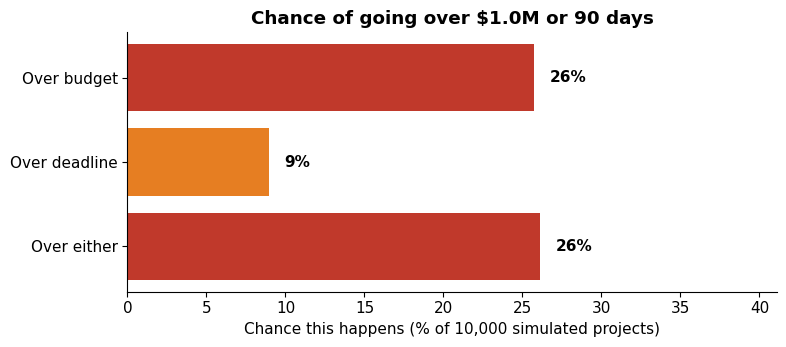

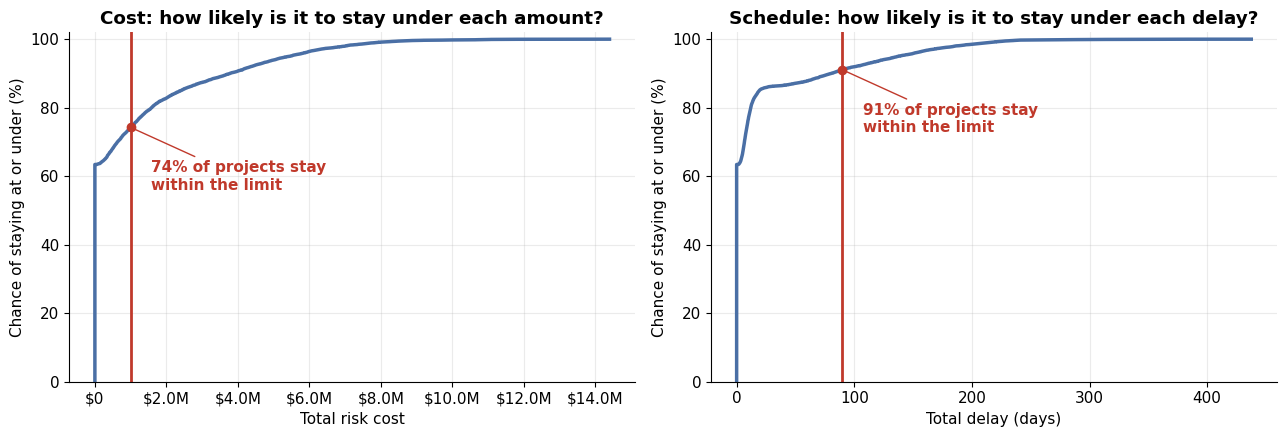

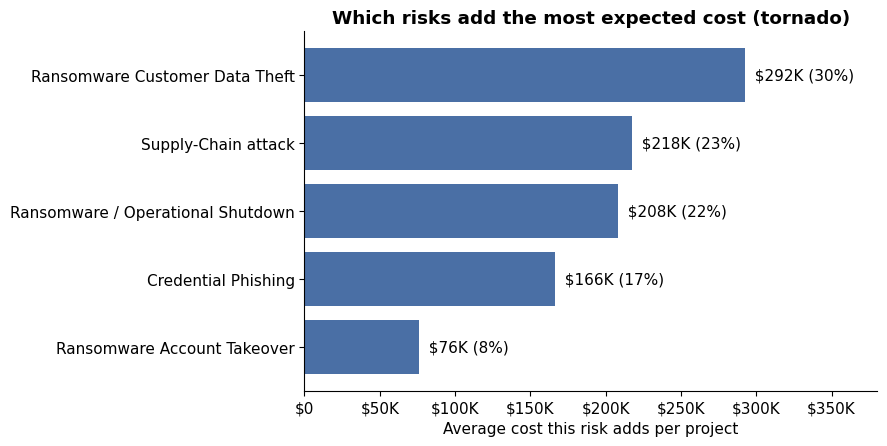

In [36]:
#@title 4. Charts { display-mode: "form" }
from matplotlib.ticker import FuncFormatter
NAVY, BLUE, RED, ORANGE, GREEN, GRAY = "#14213A", "#4a6fa5", "#c0392b", "#e67e22", "#2e8b57", "#8a8f98"
money = FuncFormatter(lambda x, _: "$0" if x == 0 else (f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:,.0f}K"))
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# Chart 1: the headline answer
fig, a = plt.subplots(figsize=(8, 3.6))
labels = ["Over budget", "Over deadline", "Over either"]
vals = [p_over_budget * 100, p_over_time * 100, p_either * 100]
bars = a.barh(labels[::-1], vals[::-1], color=[RED, ORANGE, RED][::-1])
for bar, v in zip(bars, vals[::-1]):
    a.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%", va="center", fontweight="bold")
a.set_xlim(0, max(vals) + 15); a.set_xlabel("Chance this happens (% of 10,000 simulated projects)")
a.set_title(f"Chance of going over {money(BUDGET)} or {DEADLINE_DAYS} days", fontweight="bold")
plt.tight_layout(); plt.savefig("1_headline.png", dpi=150); plt.show()

# Chart 2: S-curves. Read it as "chance of staying at or under this amount"
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, data, limit, xlabel, fmt in [
    (ax[0], total_cost, BUDGET, "Total risk cost", money),
    (ax[1], total_days, DEADLINE_DAYS, "Total delay (days)", FuncFormatter(lambda x, _: f"{x:,.0f}"))]:
    xs = np.sort(data); ys = np.arange(1, len(xs) + 1) / len(xs) * 100
    a.plot(xs, ys, color=BLUE, lw=2.5)
    within = (data <= limit).mean() * 100
    a.axvline(limit, color=RED, lw=2)
    a.scatter([limit], [within], color=RED, zorder=5)
    a.annotate(f"{within:.0f}% of projects stay\nwithin the limit", (limit, within), xytext=(15, -45),
               textcoords="offset points", color=RED, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RED))
    a.set_xlabel(xlabel); a.set_ylabel("Chance of staying at or under (%)")
    a.xaxis.set_major_formatter(fmt); a.set_ylim(0, 102); a.grid(alpha=0.25)
ax[0].set_title("Cost: how likely is it to stay under each amount?", fontweight="bold")
ax[1].set_title("Schedule: how likely is it to stay under each delay?", fontweight="bold")
plt.tight_layout(); plt.savefig("2_s_curve.png", dpi=150); plt.show()

# Chart 3: tornado. Which risks add the most expected cost?
contrib = pd.Series(cost.mean(axis=0), index=register["risk"]).sort_values()
fig, a = plt.subplots(figsize=(9, 0.6 * len(contrib) + 1.6))
bars = a.barh(contrib.index, contrib.values, color=BLUE)
for bar, v in zip(bars, contrib.values):
    a.text(v, bar.get_y() + bar.get_height() / 2, f"  {money(v, None)} ({v / contrib.sum():.0%})", va="center")
a.set_xlim(0, contrib.max() * 1.3); a.xaxis.set_major_formatter(money)
a.set_xlabel("Average cost this risk adds per project")
a.set_title("Which risks add the most expected cost (tornado)", fontweight="bold")
plt.tight_layout(); plt.savefig("3_tornado.png", dpi=150); plt.show()
